# Đánh giá U-Net++ 2D trên BraTS 2020

Notebook đọc mask dự đoán đã khôi phục về lưới gốc, tính Dice, IoU, HD95 theo bệnh nhân và vẽ ảnh so sánh với ground truth.

Chạy lần lượt các ô bằng runtime CPU. Dữ liệu gốc tải vào `/content`, bảng kết quả và hình lưu trên Google Drive.


## 1. Chuẩn bị mã nguồn

Clone repository để lấy cấu trúc dự án và `configs/splits.json`. Nếu đã có repo trong runtime thì dùng lại thư mục đó.


In [1]:
# 1. Lấy code nền và chuyển về thư mục gốc của dự án.
import os
import sys
import subprocess
from pathlib import Path

REPO_URL = 'https://github.com/Q-Anh2610/brats-tumor-seg.git'
REPO_DIR = Path('/content/brats-eval-workspace')

if not REPO_DIR.exists():
    subprocess.run(['git', 'clone', '--branch', 'main', '--single-branch',
                    REPO_URL, str(REPO_DIR)], check=True)
else:
    assert (REPO_DIR / '.git').is_dir(), 'Kiểm tra lại thư mục repository.'

os.chdir(REPO_DIR)
print('Thư mục làm việc:', REPO_DIR)

Thư mục làm việc: /content/brats-eval-workspace


Tải lên `eval_viz_reviewed.zip` để đặt các script mới vào `src/eval/` và `src/viz/`. Code chạy trực tiếp trong runtime, chưa cần push GitHub.
Nếu đã sửa file trong runtime, lưu phần sửa trước khi upload lại vì file cùng tên sẽ được cập nhật.


In [2]:
# Nạp bộ mã từ máy và cài thư viện dùng cho đánh giá.
import io
import stat
import zipfile
from google.colab import files

SOURCE_FILES = ['notebooks/04_eval_overlay.ipynb', 'requirements-eval-viz.txt', 'src/eval/prepare_data.py', 'src/eval/nifti_io.py', 'src/eval/metrics_3d.py', 'src/eval/evaluate.py', 'src/viz/overlay.py', 'tests/test_eval_viz_midterm.py', 'docs/EVAL_VIZ_GIUA_KY.txt', 'docs/RESULTS_CHECK.txt', 'VALIDATION.txt']

uploaded = files.upload()
zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
assert len(zip_names) == 1, 'Chọn một file ZIP mã nguồn.'

with zipfile.ZipFile(io.BytesIO(uploaded[zip_names[0]])) as bundle:
    entries = [entry for entry in bundle.infolist() if not entry.is_dir()]
    names = [entry.filename for entry in entries]
    assert len(names) == len(set(names)), 'ZIP có tên file trùng.'
    assert set(names) == set(SOURCE_FILES), 'Chọn đúng file eval_viz_reviewed.zip.'

    targets = []
    for entry in entries:
        assert not stat.S_ISLNK(entry.external_attr >> 16), 'ZIP chứa symlink.'
        target = (REPO_DIR / entry.filename).resolve()
        target.relative_to(REPO_DIR.resolve())
        targets.append((entry, target))

    for entry, target in targets:
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(bundle.read(entry))

del uploaded
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                '-r', 'requirements-eval-viz.txt'], check=True)
print('Đã nạp bộ mã đánh giá.')


Saving eval_viz_reviewed.zip to eval_viz_reviewed.zip
Đã nạp bộ mã đánh giá.


## 2. Kết nối Drive và đặt đường dẫn

`PRED_DIR` chứa 55 mask dự đoán, `DRIVE_RES` là nơi lưu kết quả mới. Giữ đường dẫn dự đoán như lần chạy đã kiểm tra, sửa lại nếu dùng một tài khoản hoặc shortcut khác.


In [3]:
# 2. Mount Drive và cấu hình các đường dẫn dùng trong notebook.
from google.colab import drive
drive.mount('/content/drive')

PRED_DIR = Path('/content/drive/MyDrive/brats_midterm_unetpp/preds_test_3d')
DRIVE_RES = Path('/content/drive/MyDrive/brats_midterm_eval')
DOWNLOAD_DIR = Path('/content/brats2020_raw')
SPLITS_FILE = REPO_DIR / 'configs/splits.json'

assert PRED_DIR.is_dir(), f'Không tìm thấy thư mục dự đoán: {PRED_DIR}'
assert SPLITS_FILE.is_file()
DRIVE_RES.mkdir(parents=True, exist_ok=True)
print('Số mask dự đoán:', len(list(PRED_DIR.glob('*_pred_wt.nii.gz'))))

# Dùng cùng danh sách test với lần chạy đã kiểm tra.
import hashlib
split_hash = hashlib.sha256(SPLITS_FILE.read_bytes()).hexdigest()
assert split_hash == '90119e833025c43fc827aecc04fe79687850b88ef15eb8ed39df5dd4986a4c3b', 'Split đã thay đổi, cần đối chiếu phiên bản tạo dự đoán.'

Mounted at /content/drive
Số mask dự đoán: 55


## 3. Tải BraTS 2020 gốc

Dùng GT và MRI NIfTI gốc để đánh giá trên cùng lưới với dự đoán. File `kaggle.json` chỉ cần tải lên khi runtime chưa có cấu hình Kaggle.


In [4]:
# 3. Cấu hình Kaggle API nếu runtime chưa có thông tin xác thực

kaggle_dir = Path.home() / '.kaggle'
credentials = kaggle_dir / 'kaggle.json'

if not credentials.is_file():
    uploaded = files.upload()
    assert 'kaggle.json' in uploaded, 'Chọn file kaggle.json.'
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    credentials.write_bytes(uploaded['kaggle.json'])
    credentials.chmod(0o600)

    upload_copy = Path.cwd() / 'kaggle.json'
    if upload_copy.is_file() and upload_copy.resolve() != credentials.resolve():
        upload_copy.unlink()
    del uploaded

print('Đã có cấu hình Kaggle API.')

Saving kaggle.json to kaggle.json
Đã có cấu hình Kaggle API.


In [5]:
# Tải và giải nén dữ liệu gốc vào ổ tạm Colab.

import shutil

print(f'Dung lượng trống: {shutil.disk_usage("/content").free / 1024**3:.1f} GiB')

DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
has_cases = any(p.is_dir() and p.name.removeprefix('BraTS20_Training_').isdigit()
                for p in DOWNLOAD_DIR.rglob('BraTS20_Training_*'))
if not has_cases:
    subprocess.run(['kaggle', 'datasets', 'download',
                    '-d', 'awsaf49/brats20-dataset-training-validation',
                    '-p', str(DOWNLOAD_DIR), '--unzip'], check=True)
else:
    print('Dùng lại dữ liệu đã có trong runtime.')

Dung lượng trống: 225.7 GiB


## 4. Kiểm tra các file đầu vào

Đối chiếu danh sách test với GT, FLAIR và dự đoán. Script tìm thư mục training từ dữ liệu đã tải, sau đó lưu đường dẫn từng ca vào `input_checks/inputs_checked.json`.


In [6]:
# 4. Kiểm tra đủ file của 55 ca trước khi đọc hình học.
subprocess.run([sys.executable, '-m', 'src.eval.prepare_data',
                '--download-dir', str(DOWNLOAD_DIR),
                '--pred-dir', str(PRED_DIR),
                '--splits', str(SPLITS_FILE),
                '--out-dir', str(DRIVE_RES / 'input_checks')], check=True)

import json
input_info = json.loads((DRIVE_RES / 'input_checks/inputs_checked.json').read_text())
RAW_DIR = Path(input_info['raw_dir_runtime_only'])
print('Dữ liệu gốc:', RAW_DIR)

Dữ liệu gốc: /content/brats2020_raw/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData


## 5. Kiểm tra đơn vị và lưới không gian

GT và FLAIR của bộ dữ liệu này có đơn vị mm, cả 55 mask dự đoán có đơn vị `unknown`. Phần kiểm tra dưới đây đối chiếu lại shape, spacing và affine trước khi tính metric.

Vì vậy giữ `ASSUME_UNKNOWN_MM=True` cho bộ dự đoán này. Đoạn kiểm tra dưới đây vẫn yêu cầu GT và FLAIR có đơn vị xác định, chỉ cho phép diễn giải đơn vị còn thiếu của dự đoán là mm. File NIfTI gốc không bị sửa.


In [7]:
# 5. Kiểm tra hình học của từng ca trước khi tính khoảng cách theo mm

import nibabel as nib
import numpy as np
from collections import Counter
from src.eval.nifti_io import read_split, find_raw_file, grid_mm, same_grid

ASSUME_UNKNOWN_MM = True
case_ids = read_split(SPLITS_FILE, 'test')
assert len(case_ids) == 55
unit_counts = Counter()

for case_id in case_ids:
    paths = {
        'GT': find_raw_file(RAW_DIR, case_id, 'seg'),
        'FLAIR': find_raw_file(RAW_DIR, case_id, 'flair'),
        'Prediction': PRED_DIR / f'{case_id}_pred_wt.nii.gz',
    }
    images = {name: nib.load(str(path)) for name, path in paths.items()}

    for name, image in images.items():
        unit_counts[(name, image.header.get_xyzt_units()[0])] += 1
        allow_unknown = ASSUME_UNKNOWN_MM and name == 'Prediction'
        _, spacing_mm, _ = grid_mm(image, assume_unknown_mm=allow_unknown)
        assert image.shape == (240, 240, 155), f'{case_id}, {name}, shape={image.shape}'
        assert np.allclose(spacing_mm, [1, 1, 1], rtol=0, atol=1e-4), (
            f'{case_id}, {name}, spacing={spacing_mm}'
        )

    same_grid(images['GT'], images['FLAIR'])
    same_grid(images['GT'], images['Prediction'], ASSUME_UNKNOWN_MM)

for (name, unit), count in sorted(unit_counts.items()):
    print(f'{name}: đơn vị {unit}, {count} file')
print('55 ca khớp shape, spacing và affine.')

FLAIR: đơn vị mm, 55 file
GT: đơn vị mm, 55 file
Prediction: đơn vị unknown, 55 file
55 ca khớp shape, spacing và affine.


## 6. Kiểm thử và kiểm tra toàn tập

Bộ kiểm thử dùng dữ liệu giả để kiểm tra các công thức và trường hợp mask rỗng. Sau đó chạy `--check-only` trên dữ liệu thật, bước này kiểm tra nhãn và hình học nhưng chưa ghi bảng điểm.


In [8]:
# 6. Chạy kiểm thử trước khi đánh giá dữ liệu thật

subprocess.run([sys.executable, '-m', 'unittest', 'discover',
                '-s', 'tests', '-p', 'test_eval_viz_midterm.py', '-v'], check=True)

# Các tham số này được dùng lại cho eval và viz.
unit_flags = ['--assume-unknown-mm'] if ASSUME_UNKNOWN_MM else []
eval_args = ['--raw-dir', str(RAW_DIR), '--pred-dir', str(PRED_DIR),
             '--splits', str(SPLITS_FILE), '--split-name', 'test', *unit_flags]
viz_args = ['--raw-dir', str(RAW_DIR), '--pred-dir', str(PRED_DIR), *unit_flags]

# In cả stdout và stderr để xem được nguyên nhân nếu script báo lỗi.
result = subprocess.run([sys.executable, '-m', 'src.eval.evaluate',
                         *eval_args, '--check-only'], capture_output=True, text=True)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode != 0:
    raise RuntimeError('Kiểm tra đầu vào chưa thành công, xem log phía trên.')

[1/55] OK BraTS20_Training_004
[2/55] OK BraTS20_Training_013
[3/55] OK BraTS20_Training_014
[4/55] OK BraTS20_Training_016
[5/55] OK BraTS20_Training_017
[6/55] OK BraTS20_Training_023
[7/55] OK BraTS20_Training_041
[8/55] OK BraTS20_Training_045
[9/55] OK BraTS20_Training_048
[10/55] OK BraTS20_Training_050
[11/55] OK BraTS20_Training_053
[12/55] OK BraTS20_Training_058
[13/55] OK BraTS20_Training_064
[14/55] OK BraTS20_Training_072
[15/55] OK BraTS20_Training_080
[16/55] OK BraTS20_Training_082
[17/55] OK BraTS20_Training_102
[18/55] OK BraTS20_Training_111
[19/55] OK BraTS20_Training_112
[20/55] OK BraTS20_Training_113
[21/55] OK BraTS20_Training_115
[22/55] OK BraTS20_Training_120
[23/55] OK BraTS20_Training_126
[24/55] OK BraTS20_Training_136
[25/55] OK BraTS20_Training_141
[26/55] OK BraTS20_Training_143
[27/55] OK BraTS20_Training_151
[28/55] OK BraTS20_Training_173
[29/55] OK BraTS20_Training_175
[30/55] OK BraTS20_Training_177
[31/55] OK BraTS20_Training_184
[32/55] OK BraTS2

## 7. Chạy thử một ca

Tính metric cho một ca test và xem ba ô MRI, GT, dự đoán. Lát mặc định có diện tích GT lớn nhất sau khi đưa về RAS+, điểm trên tiêu đề là Dice của cả khối 3D.


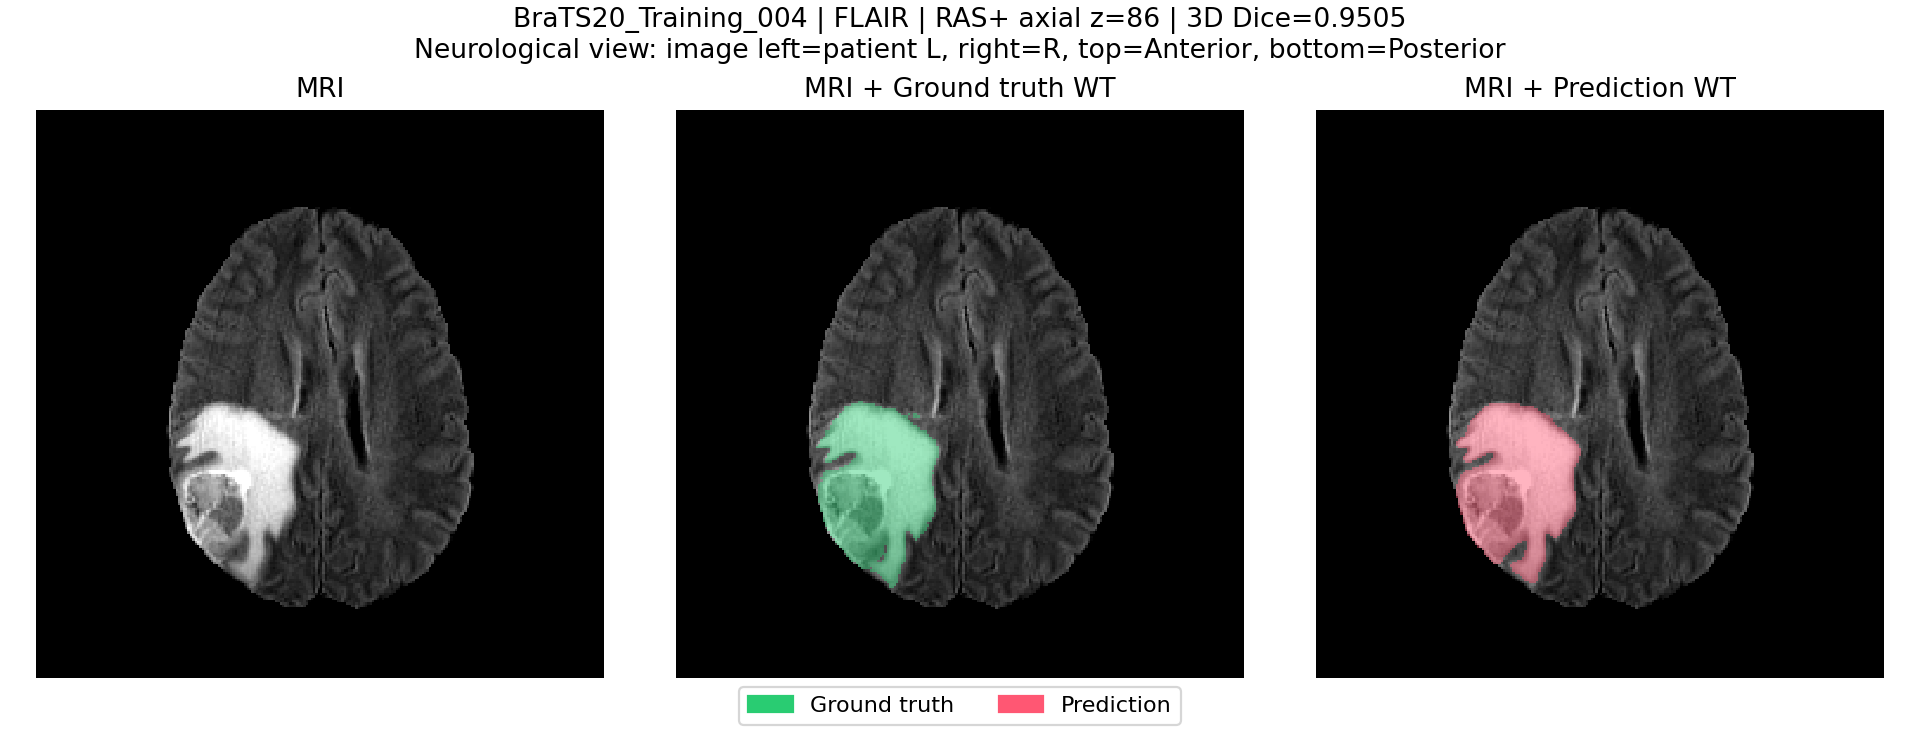

In [9]:
# 7. Kiểm tra bảng điểm và vị trí overlay trên một ca

CASE_ID = case_ids[0]
SMOKE_DIR = DRIVE_RES / 'smoke_one_case'

subprocess.run([sys.executable, '-m', 'src.eval.evaluate', *eval_args,
                '--case-id', CASE_ID, '--out-dir', str(SMOKE_DIR)], check=True)
subprocess.run([sys.executable, '-m', 'src.viz.overlay', *viz_args,
                '--case-id', CASE_ID,
                '--metrics-csv', str(SMOKE_DIR / 'per_case.csv'),
                '--out-dir', str(SMOKE_DIR / 'figures')], check=True)

from IPython.display import Image, display
for path in sorted((SMOKE_DIR / 'figures').glob('*.png')):
    display(Image(filename=str(path)))

## 8. Đánh giá 55 ca test

Mỗi bệnh nhân có một dòng Dice, IoU và HD95. Bảng tổng hợp dùng trung bình và độ lệch chuẩn mẫu với `ddof=1`.
Nếu có HD95 vô hạn, báo rõ số ca đó và thống kê nhóm hữu hạn riêng. Dùng tên thư mục lần chạy mới để giữ kết quả đã có.


In [10]:
# 8. Xuất bảng theo ca và bảng tổng hợp trên lưới gốc

OUT_DIR = DRIVE_RES / 'unetpp_test_run02'
assert not OUT_DIR.exists(), 'Thư mục kết quả đã có, đổi tên lần chạy để giữ kết quả cũ.'

subprocess.run([sys.executable, '-m', 'src.eval.evaluate', *eval_args,
                '--out-dir', str(OUT_DIR)], check=True)

import pandas as pd
per_case = pd.read_csv(OUT_DIR / 'per_case.csv')
summary = pd.read_csv(OUT_DIR / 'summary.csv')
manifest = json.loads((OUT_DIR / 'run_manifest.json').read_text())

assert len(per_case) == 55 and set(per_case['case_id']) == set(case_ids)
assert manifest['scope'] == 'full_split'
display(per_case.head())
display(summary[['metric', 'n_total', 'n_infinite', 'mean_all', 'sd_all']])
print('Số ca dự đoán rỗng:', manifest['n_pred_empty'])

,case_id,dice,iou,hd95_mm,gt_empty,pred_empty
0,BraTS20_Training_004,0.950486,0.905644,1.414214,0,0
1,BraTS20_Training_013,0.882127,0.789113,8.366600,0,0
2,BraTS20_Training_014,0.893539,0.807565,4.000000,0,0
3,BraTS20_Training_016,0.902770,0.822772,5.099020,0,0
4,BraTS20_Training_017,0.926527,0.863111,2.000000,0,0


,metric,n_total,n_infinite,mean_all,sd_all
0,dice,55,0,0.901579,0.068680
1,iou,55,0,0.827105,0.103118
2,hd95_mm,55,0,10.104622,16.987829


Số ca dự đoán rỗng: 0


## 9. Vẽ các ca đại diện

Chọn hai ca Dice thấp nhất, hai ca quanh trung vị và hai ca cao nhất. Ba nhóm không trùng bệnh nhân, tên ca và lát đã chọn được lưu trong `selection.json`.


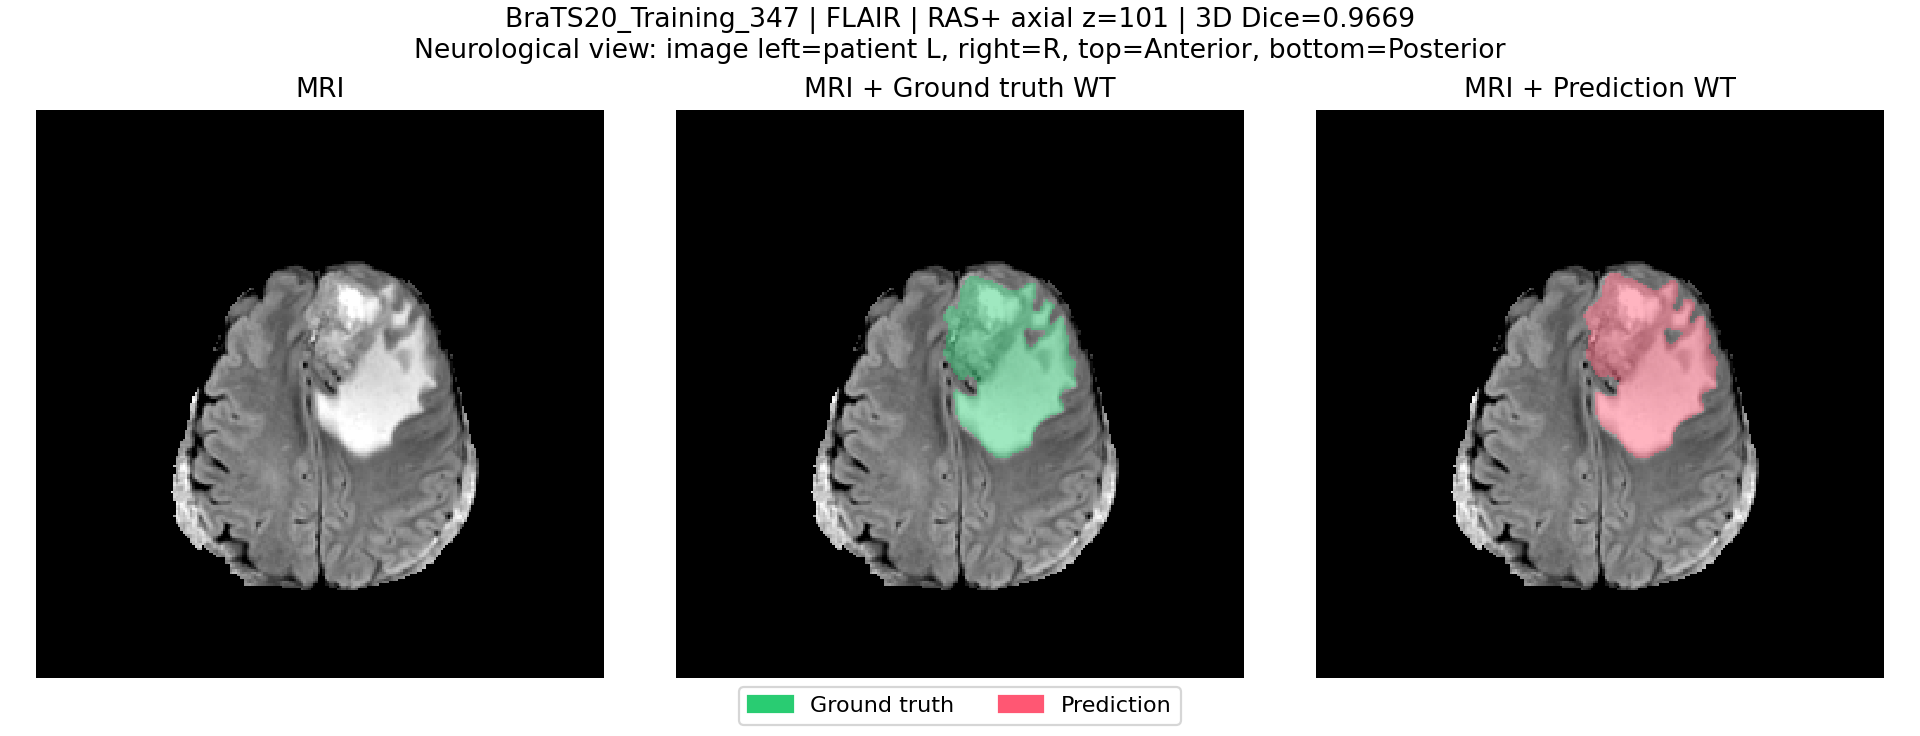

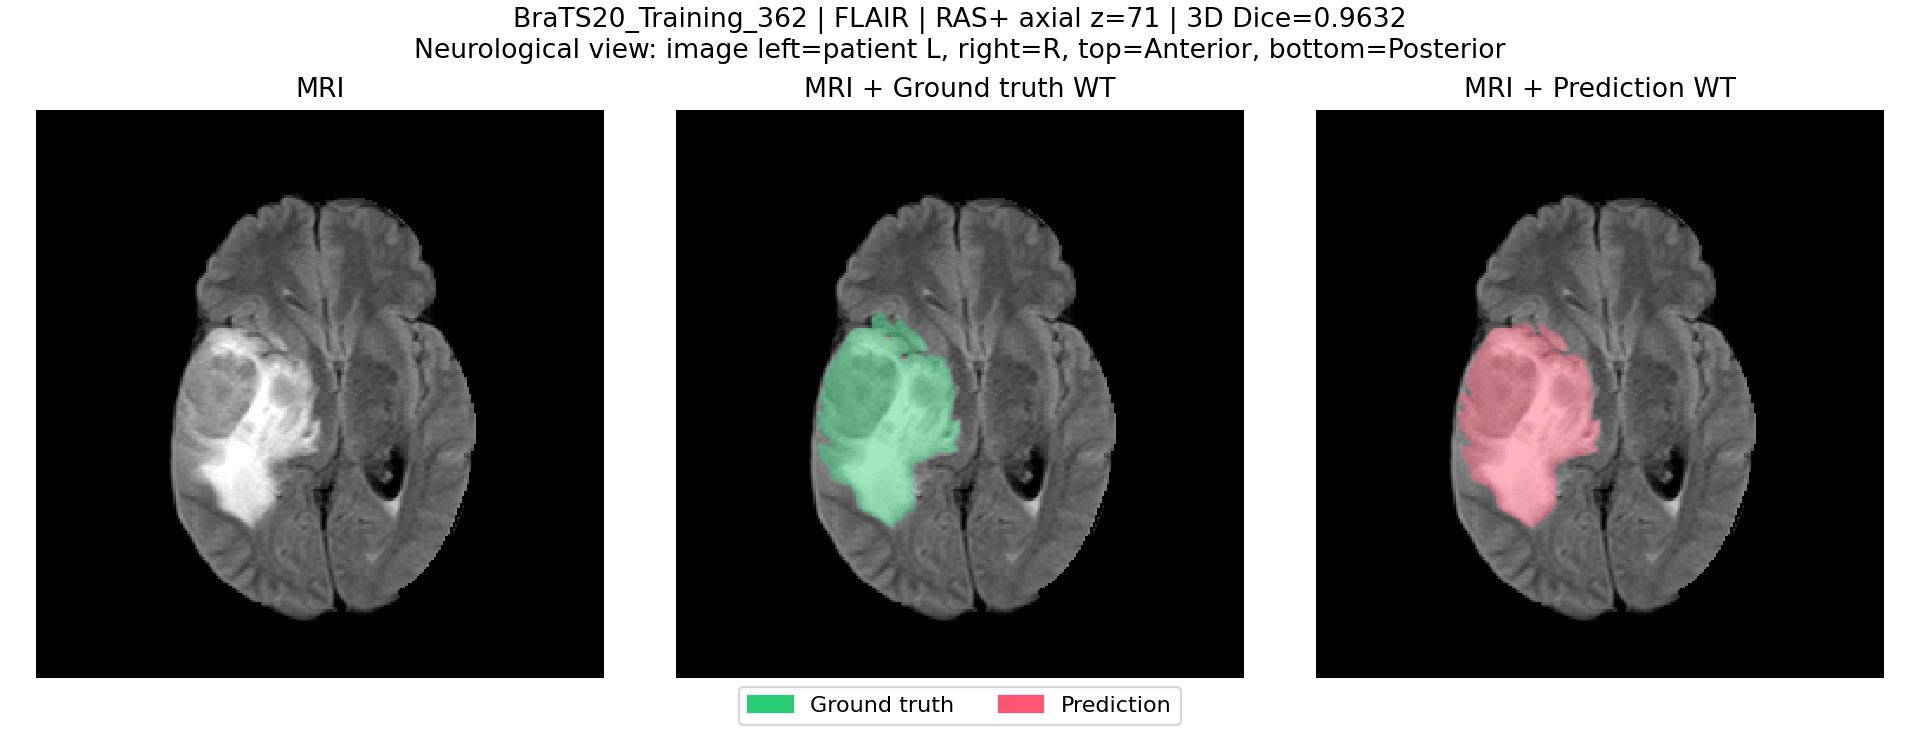

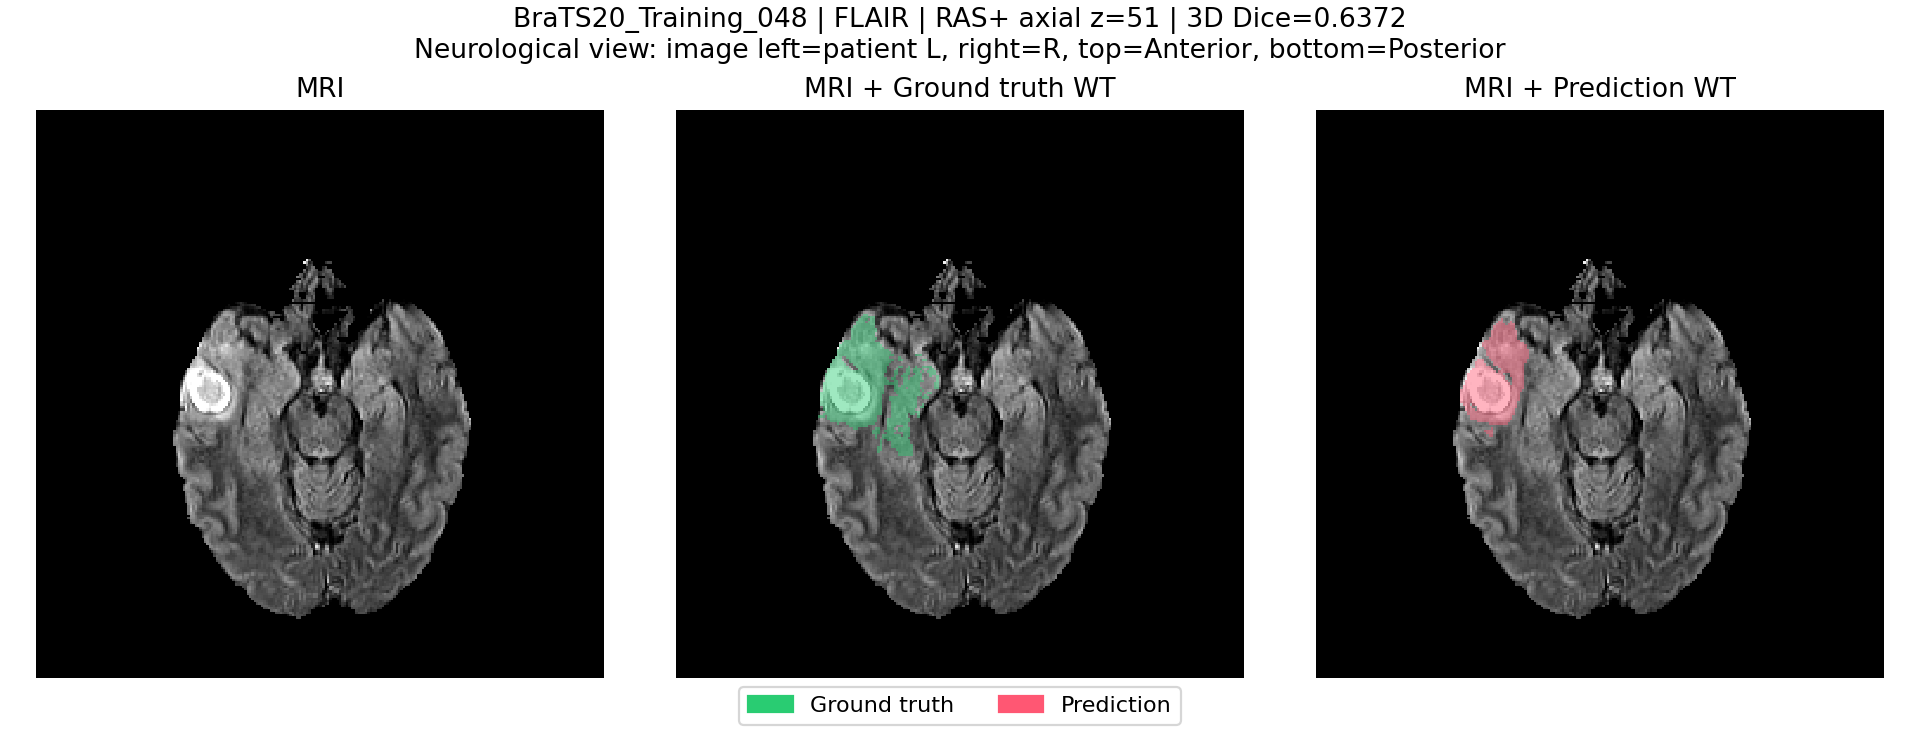

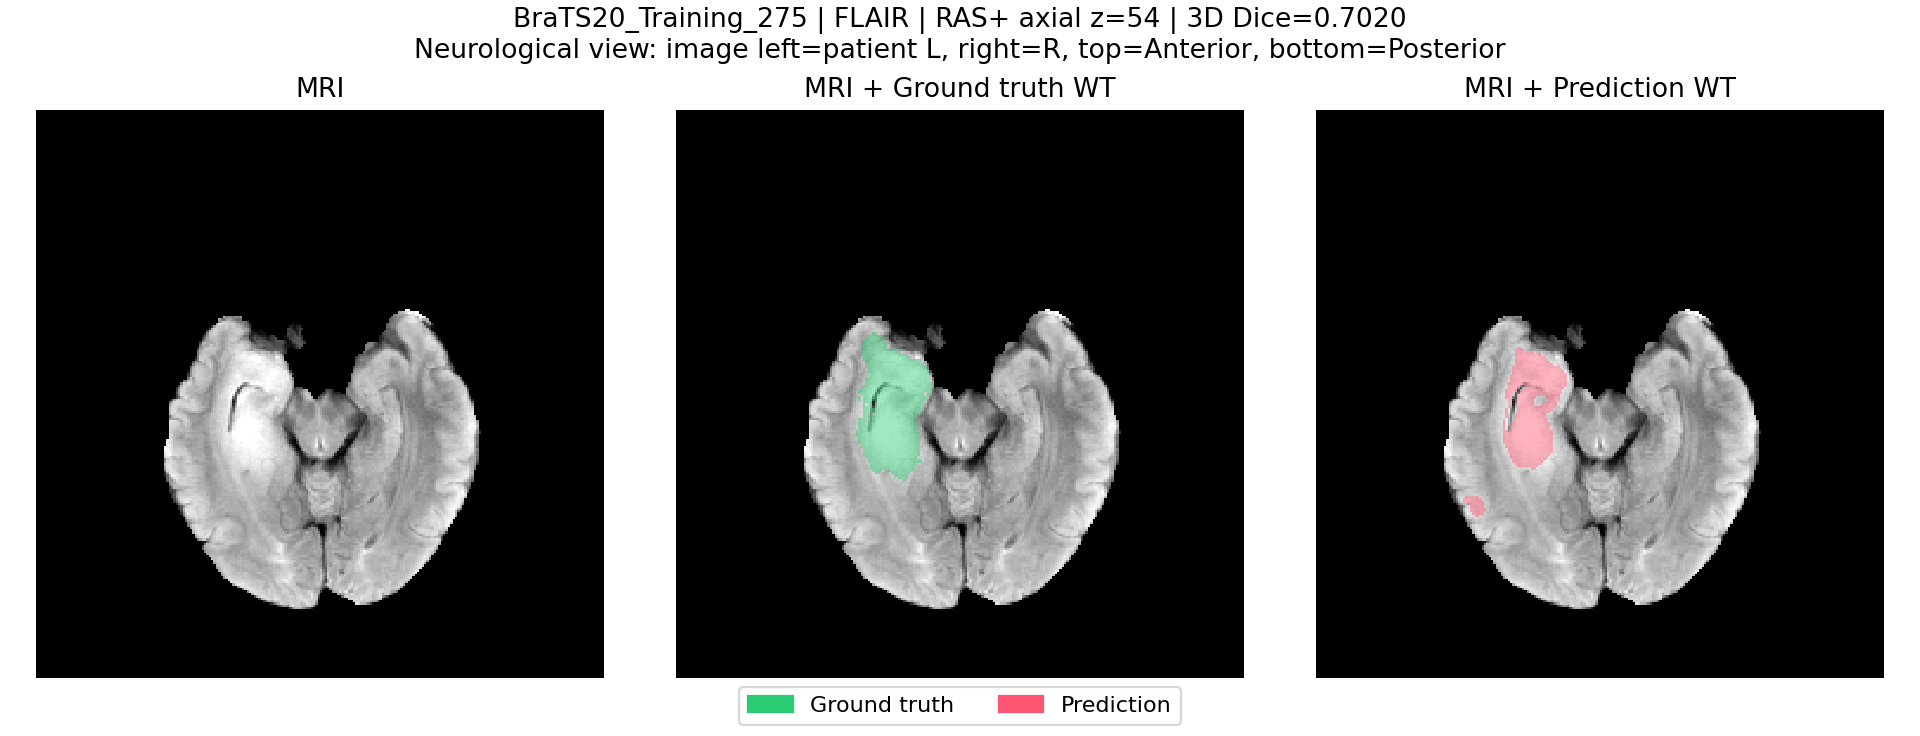

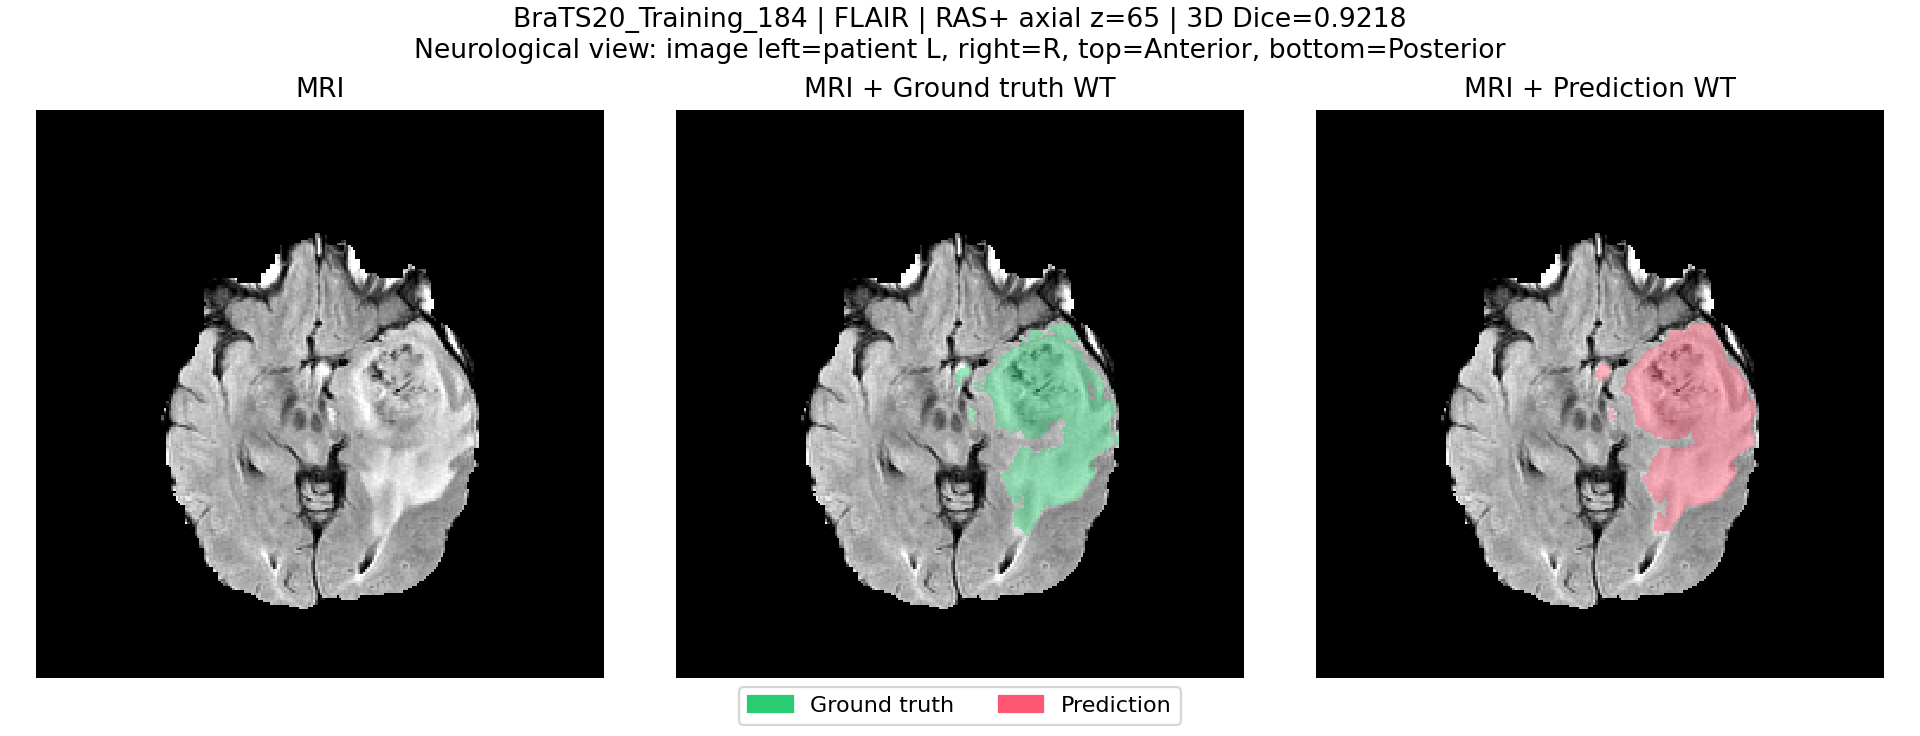

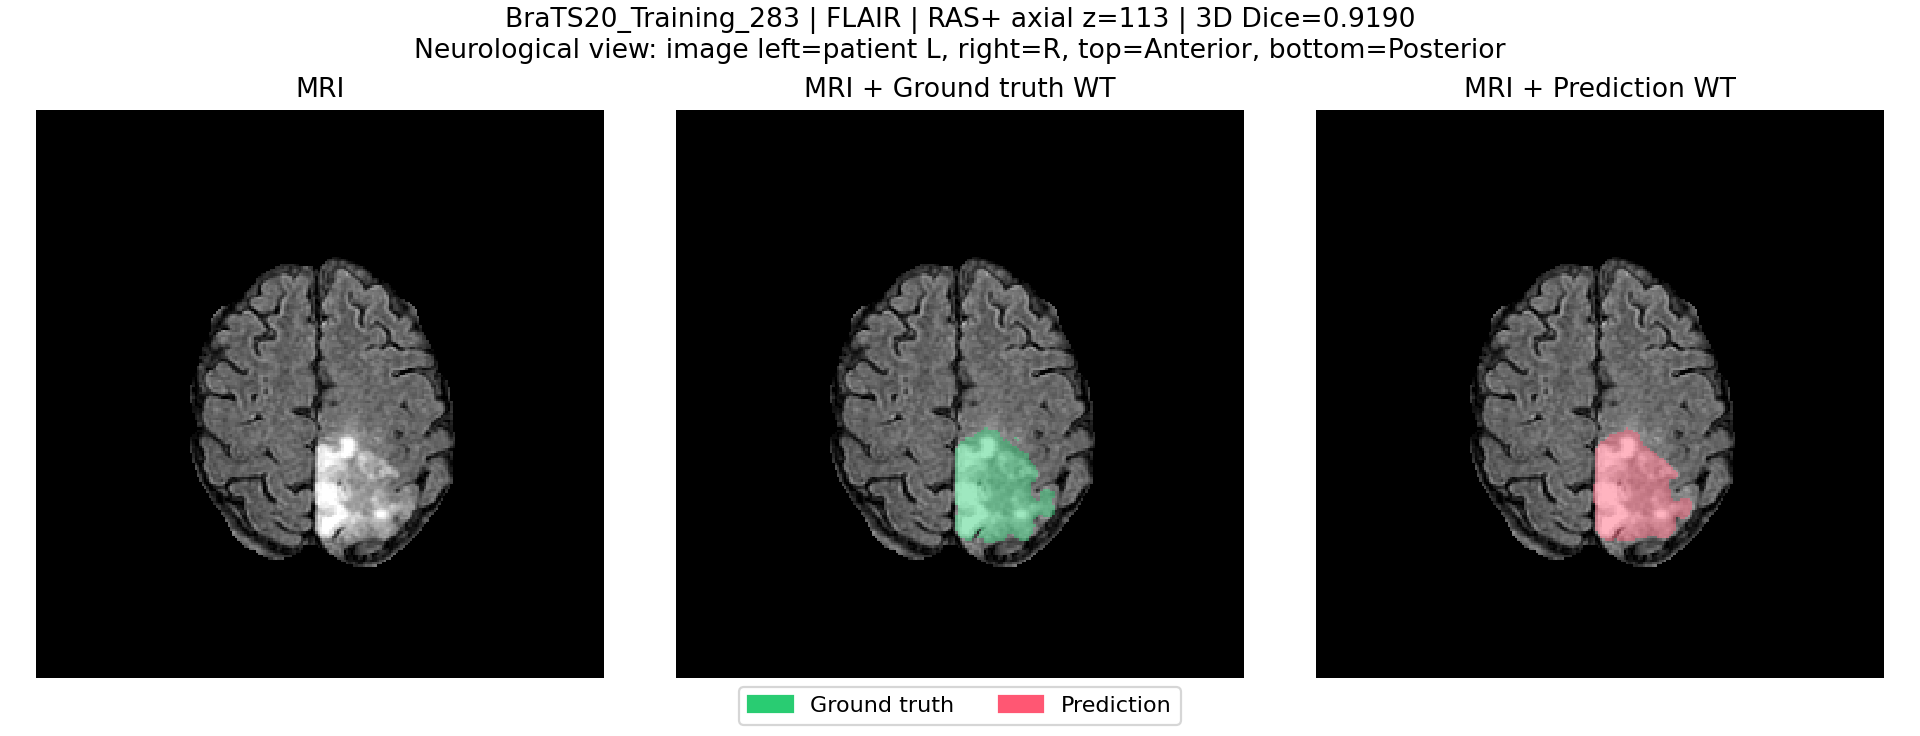

In [11]:
# 9. Vẽ overlay từ bảng Dice 3D vừa tính.

FIG_DIR = OUT_DIR / 'figures'
subprocess.run([sys.executable, '-m', 'src.viz.overlay', *viz_args,
                '--metrics-csv', str(OUT_DIR / 'per_case.csv'),
                '--channel', 'flair', '--per-group', '2',
                '--out-dir', str(FIG_DIR)], check=True)

for path in sorted(FIG_DIR.glob('*.png')):
    display(Image(filename=str(path)))

Có thể chọn thêm một ca và chỉ số lát RAS+ để xem vùng bỏ sót. Để `CUSTOM_CASE=None` nếu không cần tạo hình bổ sung.


In [12]:
# Vẽ thêm một lát cụ thể nếu cần phân tích lỗi.

CUSTOM_CASE = None
SLICE_INDEX = None

if CUSTOM_CASE is not None:
    assert CUSTOM_CASE in case_ids
    slice_args = [] if SLICE_INDEX is None else ['--slice-index', str(SLICE_INDEX)]
    subprocess.run([sys.executable, '-m', 'src.viz.overlay', *viz_args,
                    '--case-id', CUSTOM_CASE,
                    '--metrics-csv', str(OUT_DIR / 'per_case.csv'),
                    '--out-dir', str(OUT_DIR / 'extra_figures'), *slice_args], check=True)

## 10. Lưu kết quả và mã nguồn đã chạy

Ghi phiên bản thư viện, đóng gói bảng điểm và hình để tải về. ZIP nguồn chỉ chứa các file công cụ, không chứa MRI, mask dự đoán hoặc thông tin xác thực.
Sau khi kiểm tra kết quả, đưa đúng mã đã chạy về repo cục bộ rồi commit và push. Lưu thêm notebook đang mở nếu muốn giữ các output của lần chạy.


In [13]:
# 10. Giữ lại môi trường và các file dùng cho lần đánh giá này.

freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
(OUT_DIR / 'environment_freeze.txt').write_text(freeze, encoding='utf-8')

result_zip = shutil.make_archive(str(DRIVE_RES / 'eval_viz_results_run02'),
                                  'zip', root_dir=OUT_DIR)
source_zip = DRIVE_RES / 'eval_viz_tested_source_run02.zip'
with zipfile.ZipFile(source_zip, 'w', zipfile.ZIP_DEFLATED) as bundle:
    for relative in SOURCE_FILES:
        path = REPO_DIR / relative
        if path.is_file():
            bundle.write(path, relative)

print('Kết quả:', OUT_DIR)
print('ZIP kết quả:', result_zip)
print('ZIP nguồn:', source_zip)
files.download(result_zip)
# Có thể tải ZIP nguồn bằng files.download(str(source_zip)).

Kết quả: /content/drive/MyDrive/brats_midterm_eval/unetpp_test_run02
ZIP kết quả: /content/drive/MyDrive/brats_midterm_eval/eval_viz_results_run02.zip
ZIP nguồn: /content/drive/MyDrive/brats_midterm_eval/eval_viz_tested_source_run02.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>